In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb, to_hex
from pathlib import Path
import json

In [2]:
def plot_loss(history):
    plt.figure(figsize=(8, 5))

    plt.plot(
        history["epoch"],
        history["train_loss"],
        marker="o",
        label="Training Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training Loss over Epochs")

    plt.grid(True)
    plt.legend()

    plt.show()

In [3]:
def plot_val_metrics(history):
    plt.figure(figsize=(8, 5))

    plt.plot(
        history["epoch"],
        history["val_precision"],
        marker="o",
        label="Precision"
    )

    plt.plot(
        history["epoch"],
        history["val_recall"],
        marker="o",
        label="Recall"
    )

    plt.plot(
        history["epoch"],
        history["val_f1"],
        marker="o",
        label="F1"
    )

    best_epoch = history.loc[
        history["val_f1"].idxmax(),
        "epoch"
    ]

    best_f1 = history["val_f1"].max()

    plt.scatter(
        best_epoch,
        best_f1,
        s=100,
        label=f"Best F1={best_f1:.3f}"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Score")
    plt.title("Validation Metrics")

    plt.ylim(0, 1)
    plt.grid(True)
    plt.legend()

    plt.show()

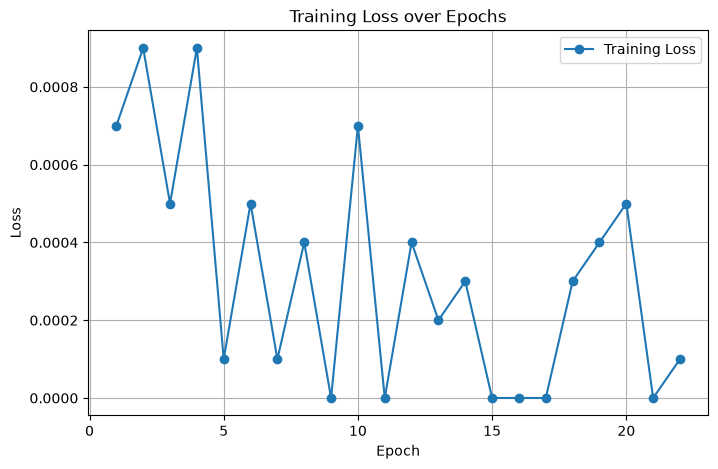

In [8]:
report_path = Path("../data/train-reports/training_history_2026_08_03-16_50_03.csv")

history = pd.read_csv(report_path)

history.head()
plot_loss(history)

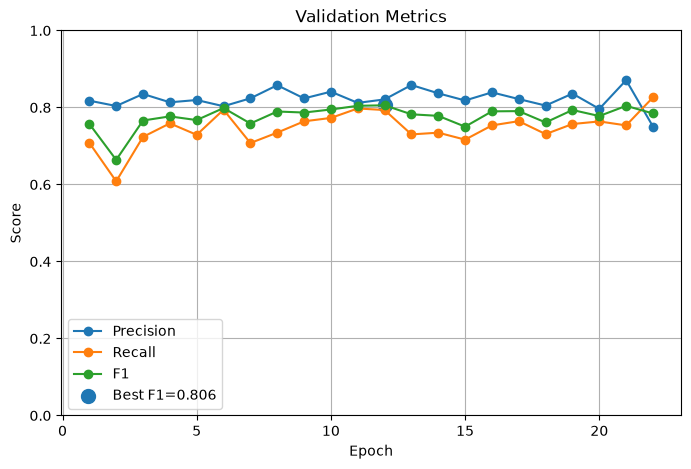

In [9]:
plot_val_metrics(history)

# Test Metrics

## Span Metrics

In [42]:
bilstm_tests = [
    (
        Path("../data/test_reports/2026_10_14-12_01_06.csv"),
        "Bi-LSTM Redewiedergabe Embedding"
    ),
    (
        Path("../data/test_reports/2026_10_14-13_55_50_hamburgeranzeiger.csv"),
        "Bi-LSTM Hamburger Anzeiger Embedding"
    ),
]

records = []

for csv_path, model_name in bilstm_tests:
    df = pd.read_csv(csv_path, index_col=0)

    records.append({
        "model": model_name,
        "span_precision": round(float(df.loc["span_precision", "precision"]), 2),
        "span_recall": round(float(df.loc["span_recall", "recall"]), 2),
        "span_f1": round(float(df.loc["span_f1", "f1-score"]), 2),
    })

out_path = Path("../evaluation/bilstm_span_metrics.json")
out_path.write_text(
    json.dumps(records, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

267

In [13]:
roberta_test_path = Path("../transformer/test_results/2026_10_14-14_46_21_test_results.json")

with roberta_test_path.open("r", encoding="utf-8") as f:
    roberta_test = json.load(f)

span = roberta_test["test_results"]["span_metrics"]

roberta_test_metrics = {
    "model": "RoBERTa FacebookAI/xlm-roberta-large-finetuned-conll03-german",
    "span_precision": round(float(span["precision"]), 2),
    "span_recall": round(float(span["recall"]), 2),
    "span_f1": round(float(span["f1"]), 2),
}

out_path = Path("../evaluation/roberta_span_metrics.json")
out_path.write_text(
    json.dumps(roberta_test_metrics, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

146

In [14]:
ollama_test_path = Path("../ollama_files")

records = []

for file_path in sorted(ollama_test_path.glob("test_result*.json")):
    with file_path.open("r", encoding="utf-8") as f:
        data = json.load(f)

    records.append({
        "model": data.get("model"),
        "span_precision": round(float(data.get("span_precision", 0)), 2),
        "span_recall": round(float(data.get("span_recall", 0)), 2),
        "span_f1": round(float(data.get("span_f1", 0)), 2),
    })

out_path = Path("../evaluation/ollama_span_metrics.json")
out_path.write_text(
    json.dumps(records, ensure_ascii=False, indent=2),
    encoding="utf-8"
)


447

In [31]:
JSON_FILES = [
    "bilstm_span_metrics.json",
    "roberta_span_metrics.json",
    "ollama_span_metrics.json",
]

METRICS = ["Span Precision", "Span Recall", "Span-F1"]

FILE_BASE_COLORS = [
    "#2563A6",  # Blau
    "#D97706",  # Orange
    "#23856D",  # Grün
]

def lighten_color(color, amount):
    """Mischt eine Farbe mit Weiß."""
    rgb = np.array(to_rgb(color))
    return to_hex(rgb + (1 - rgb) * amount)


def load_json_entries(path):
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    # Einzelnes Objekt, Liste oder {"results": [...]}
    if isinstance(data, dict) and "results" in data:
        data = data["results"]

    if isinstance(data, dict):
        data = [data]
    elif not isinstance(data, list):
        raise ValueError(f"Ungültiges JSON-Format: {path}")

    rows = []
    for i, entry in enumerate(data, start=1):
        required = [
            "model", "span_precision", "span_recall", "span_f1"
        ]
        missing = [key for key in required if key not in entry]

        if missing:
            raise ValueError(
                f"{path}, Eintrag {i}: fehlende Schlüssel {missing}"
            )

        rows.append({
            "model": str(entry["model"]),
            "Span Precision": float(entry["span_precision"]),
            "Span Recall": float(entry["span_recall"]),
            "Span-F1": float(entry["span_f1"]),
            "source_file": Path(path).name,
        })

    return rows


def load_all_files(paths):
    rows = []

    for file_index, path in enumerate(paths):
        entries = load_json_entries(path)
        base_color = FILE_BASE_COLORS[
            file_index % len(FILE_BASE_COLORS)
        ]

        # Modelle derselben Datei erhalten ähnliche Farbtöne
        if len(entries) == 1:
            shades = [lighten_color(base_color, 0.12)]
        else:
            amounts = np.linspace(0.55, 0.05, len(entries))
            shades = [
                lighten_color(base_color, amount)
                for amount in amounts
            ]

        for entry, shade in zip(entries, shades):
            entry["color"] = shade
            rows.append(entry)

    return pd.DataFrame(rows)

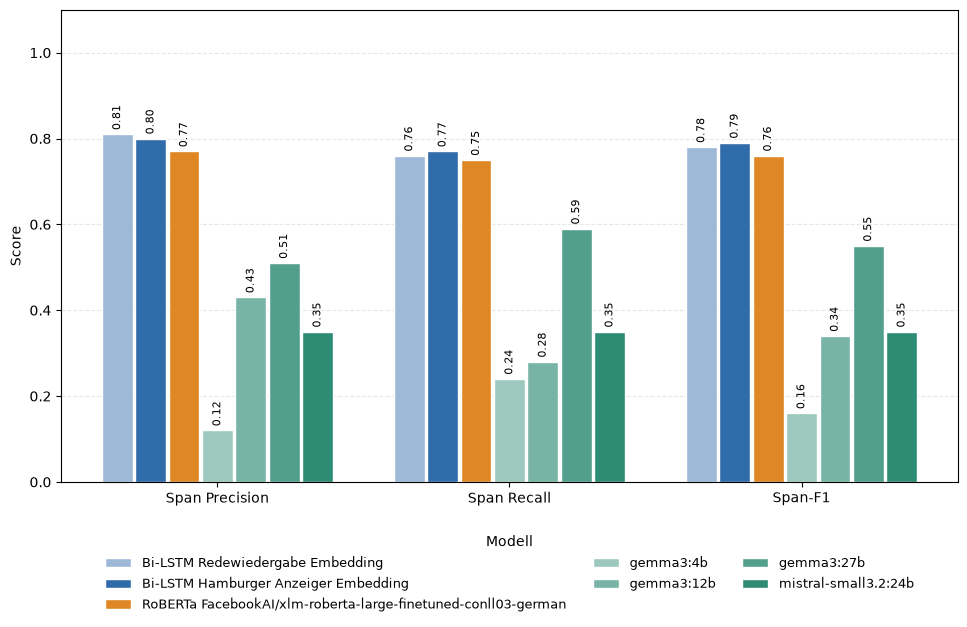

In [36]:
def plot_span_metrics(results):
    n_models = len(results)
    x = np.arange(len(METRICS))

    bar_width = min(0.8 / n_models, 0.22)
    offsets = (
        np.arange(n_models) - (n_models - 1) / 2
    ) * bar_width

    fig, ax = plt.subplots(
        figsize=(max(10, 7 + n_models * 0.4), 6)
    )

    for i, (_, row) in enumerate(results.iterrows()):
        values = [row[m] for m in METRICS]

        bars = ax.bar(
            x + offsets[i],
            values,
            width=bar_width * 0.92,
            color=row["color"],
            edgecolor="white",
            label=f'{row["model"]}',
        )

        # Werte über den Balken anzeigen
        for bar, value in zip(bars, values):
            ax.annotate(
                f"{value:.2f}",
                (bar.get_x() + bar.get_width() / 2,
                 bar.get_height()),
                xytext=(0, 3),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
                rotation=90 if n_models >= 5 else 0,
            )

    ax.set_xticks(x)
    ax.set_xticklabels(METRICS)
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.1)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    ax.legend(
        title="Modell",
        bbox_to_anchor=(0.5, -0.3),
        loc="lower center",
        ncol=3,
        fontsize=9.5,
        frameon=False,
    )
    fig.subplots_adjust(bottom=0.30)

    fig.tight_layout()
    plt.show()


# Ergebnisse einlesen und Plot im Notebook anzeigen
results = load_all_files(JSON_FILES)

plot_span_metrics(results)

## Token Metrics

In [43]:
combined = []

for csv_path, model_name in bilstm_tests:
    df = pd.read_csv(csv_path, index_col=0)

    token_metrics = {}

    for label, metrics in sorted(df.iterrows()):
        # echte Labels + macro avg, aber nicht "accuracy", "weighted avg", "span_*"
        if label in {"accuracy", "weighted avg", "span_precision", "span_recall", "span_f1"}:
            continue

        token_metrics[label] = {
            "precision": round(float(metrics["precision"]), 2),
            "recall": round(float(metrics["recall"]), 2),
            "f1-score": round(float(metrics["f1-score"]), 2),
        }

    combined.append({
        "model": model_name,
        "token_metrics": token_metrics
    })

out_path = Path("../evaluation/bilstm_token_metrics.json")
out_path.write_text(
    json.dumps(combined, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

1468

In [41]:
token_metrics = roberta_test["test_results"]["token_metrics"]
label_metrics = {
    "model": "RoBERTa FacebookAI/xlm-roberta-large-finetuned-conll03-german",
    "token_metrics": {}
}


for label, metrics in sorted(token_metrics.items()):
    if label in {"accuracy", "weighted avg"}:
        continue  # nur echte Labels, keine Aggregatswerte

    label_metrics["token_metrics"][label] = {
        "precision": round(float(metrics["precision"]), 2),
        "recall": round(float(metrics["recall"]), 2),
        "f1-score": round(float(metrics["f1-score"]), 2),
    }

out_path = Path("../evaluation/roberta_token_metrics.json")
out_path.write_text(
    json.dumps(label_metrics, ensure_ascii=False, indent=2),
    encoding="utf-8")

688

In [64]:
JSON_TOKEN_FILES = [
    "bilstm_token_metrics.json",
    "roberta_token_metrics.json",
]

LABELS = [
    "B-FUZZY_LOC",
    "I-FUZZY_LOC",
    "B-METAPHORIC_LOC",
    "I-METAPHORIC_LOC",
    "O",
    "macro avg"
]

LABEL_DISPLAY = {
    "B-FUZZY_LOC": "B-VAGUE_LOC",
    "I-FUZZY_LOC": "I-VAGUE_LOC",
    "B-METAPHORIC_LOC": "B-CONCEPTUAL_LOC",
    "I-METAPHORIC_LOC": "I-CONCEPTUAL_LOC",
    "O": "O",
    "macro avg": "Macro Average",
}

LABELS = list(LABEL_DISPLAY.keys())

METRICS = ["precision", "recall", "f1-score"]

METRIC_LABELS = ["Precision", "Recall", "F1"]


def load_json_entries_token(path):
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    # Einzelnes Objekt, Liste oder {"results": [...]}
    if isinstance(data, dict) and "results" in data:
        data = data["results"]

    if isinstance(data, dict):
        data = [data]
    elif not isinstance(data, list):
        raise ValueError(f"Ungültiges JSON-Format: {path}")

    rows = []

    for i, entry in enumerate(data, start=1):
        required = ["model", "token_metrics"]
        missing = [key for key in required if key not in entry]

        if missing:
            raise ValueError(
                f"{path}, Eintrag {i}: fehlende Schlüssel {missing}"
            )

        rows.append({
            "model": str(entry["model"]),
            "token_metrics": entry["token_metrics"],
            "source_file": Path(path).name,
        })

    return rows

def load_all_token_files(paths):
    models = []

    for file_index, path in enumerate(paths):
        entries = load_json_entries_token(path)

        # Grundfarbe wird anhand der Dateiposition gewählt
        base_color = FILE_BASE_COLORS[
            file_index % len(FILE_BASE_COLORS)
        ]

        # Anzahl der Einträge bestimmt die Farbabstufungen
        if len(entries) == 1:
            shades = [lighten_color(base_color, 0.12)]
        else:
            amounts = np.linspace(0.55, 0.05, len(entries))
            shades = [
                lighten_color(base_color, amount)
                for amount in amounts
            ]

        for entry, shade in zip(entries, shades):
            entry["color"] = shade
            models.append(entry)

    return models


models = load_all_token_files(JSON_TOKEN_FILES)

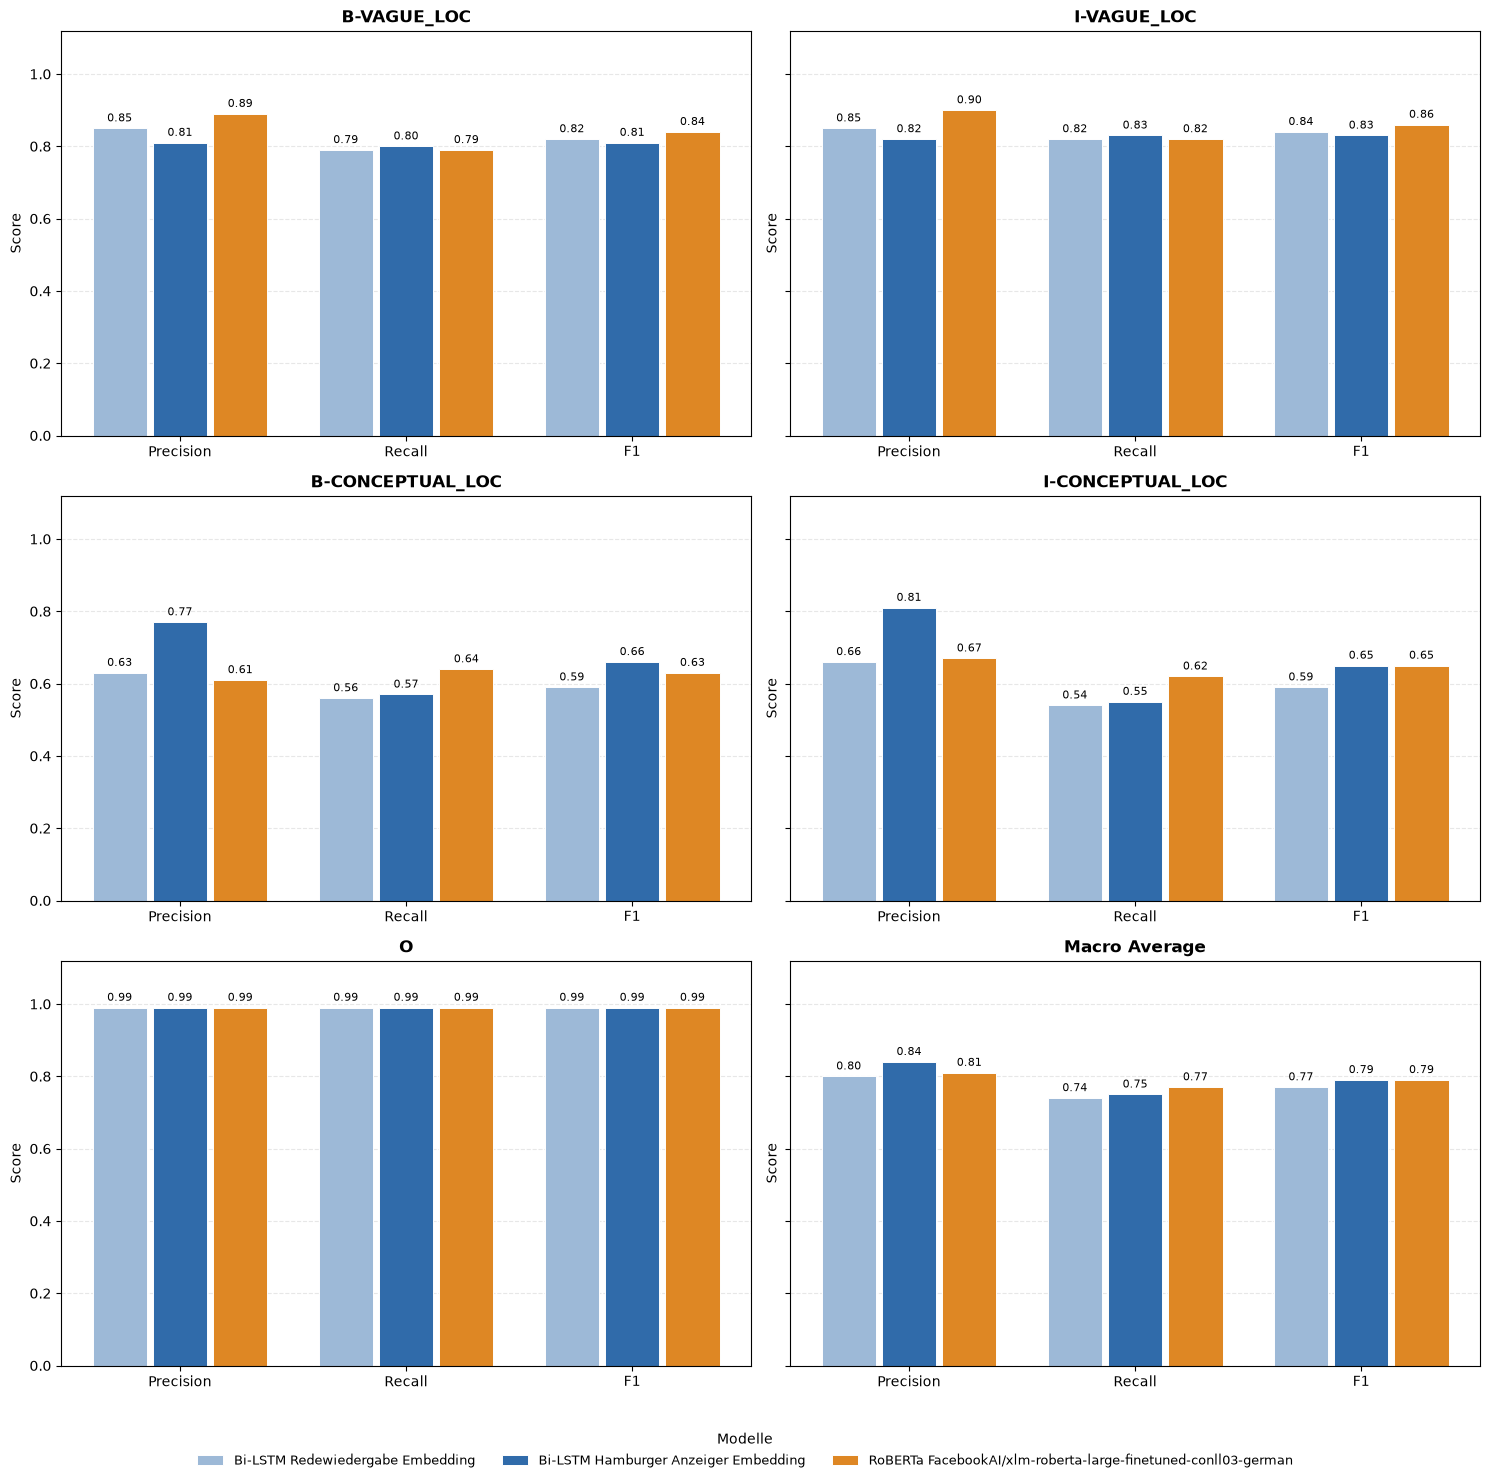

In [66]:
def plot_label_metrics(models, labels):
    # 2 Spalten, 3 Zeilen; das sechste Feld bleibt leer
    ncols = 2
    nrows = (len(labels) + ncols - 1) // ncols

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(15, 5 * nrows),
        sharey=True,
    )

    axes = np.array(axes).flatten()

    n_models = len(models)
    x = np.arange(len(METRICS))
    bar_width = 0.8 / n_models

    for label_index, label in enumerate(labels):
        ax = axes[label_index]

        for model_index, model in enumerate(models):
            label_data = model["token_metrics"].get(label)

            if label_data is None:
                print(
                    f"Warnung: Label '{label}' fehlt bei "
                    f"{model['model']}."
                )
                continue

            values = [
                label_data.get(metric, np.nan)
                for metric in METRICS
            ]

            # Balken der Modelle nebeneinander
            offsets = (
                model_index - (n_models - 1) / 2
            ) * bar_width

            bars = ax.bar(
                x + offsets,
                values,
                width=bar_width * 0.9,
                color=model["color"],
                edgecolor="white",
                linewidth=0.7,
                label=model["model"],
            )

            # Werte auf den Balken anzeigen
            for bar, value in zip(bars, values):
                if np.isfinite(value):
                    ax.annotate(
                        f"{value:.2f}",
                        (
                            bar.get_x() + bar.get_width() / 2,
                            bar.get_height(),
                        ),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha="center",
                        va="bottom",
                        fontsize=8,
                    )

        # Formatierung pro Label
        ax.set_title(LABEL_DISPLAY.get(label, label), fontsize=12, fontweight="bold")
        ax.set_xticks(x)
        ax.set_xticklabels(METRIC_LABELS)
        ax.set_ylim(0, 1.12)
        ax.set_ylabel("Score")
        ax.grid(axis="y", linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)

    # Leeres sechstes Feld entfernen
    for ax in axes[len(labels):]:
        ax.set_visible(False)

    # Eine gemeinsame Legende für alle fünf Diagramme
    handles, legend_labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        legend_labels,
        title="Modelle",
        loc="lower center",
        bbox_to_anchor=(0.5, -0.05),
        ncol=min(n_models, 3),
        fontsize=9.5,
        frameon=False,
    )


    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

plot_label_metrics(models, LABELS)